<a href="https://colab.research.google.com/github/theochi/MachineLearning/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task 1: Load Dataset**

In [1]:
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
cols = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach",
        "exang","oldpeak","slope","ca","thal","num"]
df = pd.read_csv(url, names=cols, na_values="?")

- This piece of code loads the data from UCI into the google colab so it can be used. It's also given columns that will put the data into sections.

**Task 2: Use Structural Inspection Methods**

In [2]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
print(f"Dataset shape: {df.shape[0]} rows (patients) x {df.shape[1]} columns\n")

continuous_cols  = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

print("=" * 70, "\nFirst Five Rows: df.head()\n" + "=" * 70)
display(df.head())

print("=" * 70, "\nStructure and Data Types: df.info()\n" + "=" * 70)
df.info()

print("\n" + "=" * 70, "\nContinuous Features: describe()\n" + "=" * 70)
display(df[continuous_cols].describe().round(2))

print("=" * 70, "\nCategorical Features: describe()\n" + "=" * 70)
display(df[categorical_cols].astype(str).describe())

print("=" * 70, "\nCategoray Level Frequencies\n" + "=" * 70)
for col in categorical_cols:
    print(f"{col:8s} -> {df[col].value_counts(dropna=False).sort_index().to_dict()}")

print("\nOriginal diagnosis column 'num' (0 = no disease, 1-4 = disease):")
print(df["num"].value_counts().sort_index().to_dict())

Dataset shape: 303 rows (patients) x 14 columns

First Five Rows: df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Structure and Data Types: df.info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Continuous Features: describe()


,age,trestbps,chol,thalach,oldpeak
count,303.00,303.00,303.00,303.00,303.00
mean,54.44,131.69,246.69,149.61,1.04
std,9.04,17.60,51.78,22.88,1.16
min,29.00,94.00,126.00,71.00,0.00
25%,48.00,120.00,211.00,133.50,0.00
50%,56.00,130.00,241.00,153.00,0.80
75%,61.00,140.00,275.00,166.00,1.60
max,77.00,200.00,564.00,202.00,6.20


Categorical Features: describe()


,sex,cp,fbs,restecg,exang,slope,ca,thal
count,303,303,303,303,303,303,303,303
unique,2,4,2,3,2,3,5,4
top,1.0,4.0,0.0,0.0,0.0,1.0,0.0,3.0
freq,206,144,258,151,204,142,176,166


Categoray Level Frequencies
sex      -> {0.0: 97, 1.0: 206}
cp       -> {1.0: 23, 2.0: 50, 3.0: 86, 4.0: 144}
fbs      -> {0.0: 258, 1.0: 45}
restecg  -> {0.0: 151, 1.0: 4, 2.0: 148}
exang    -> {0.0: 204, 1.0: 99}
slope    -> {1.0: 142, 2.0: 140, 3.0: 21}
ca       -> {0.0: 176, 1.0: 65, 2.0: 38, 3.0: 20, nan: 4}
thal     -> {3.0: 166, 6.0: 18, 7.0: 117, nan: 2}

Original diagnosis column 'num' (0 = no disease, 1-4 = disease):
{0: 164, 1: 55, 2: 36, 3: 35, 4: 13}


- This piece of code looks at the data to see what it looks like. It uses head(), info(), and describe(). It also separates the columns into numbers and categories and shows that some data is missing in the ca and thal columns.

**Task 3: Quantify and Handle Values**

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

print("Missing (NaN) count per column:")
print(df.isna().sum().to_dict())

placeholders = ["?", "", " ", "NA", "N/A", "-"]
remaining = {col: int(df[col].astype(str).str.strip().isin(placeholders).sum())
             for col in df.columns}
found = {col: n for col, n in remaining.items() if n > 0}
print("\nRemaining placeholder strings found:", found if found else "none")

df = df.replace(placeholders, np.nan)
df = df.apply(pd.to_numeric, errors="coerce")

zero_check = {col: int((df[col] == 0).sum()) for col in ["trestbps", "chol"]}
print("\nImpossible zero values in trestbps / chol:", zero_check)

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
print(f"\nAll columns numeric: {all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes)}")
print("\nMissing value summary:")
display(missing_summary[missing_summary["missing_count"] > 0])
print(f"Total missing cells: {int(df.isna().sum().sum())} | "
      f"Patients with at least one missing value: {int(df.isna().any(axis=1).sum())} of {len(df)}")

df["target"] = (df["num"] > 0).astype(int)
X = df.drop(columns=["num", "target"])
y = df["target"]
print("\nBinary target distribution:", y.value_counts().sort_index().to_dict())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Training set: {X_train.shape} | Test set: {X_test.shape}")

cols_with_missing = X.columns[X.isna().any()].tolist()
mode_imputer = SimpleImputer(strategy="most_frequent")
mode_imputer.fit(X_train[cols_with_missing])
print(f"\nImputation values learned from training data: "
      f"{dict(zip(cols_with_missing, mode_imputer.statistics_))}")

X_train_check = X_train.copy()
X_test_check = X_test.copy()
X_train_check[cols_with_missing] = mode_imputer.transform(X_train[cols_with_missing])
X_test_check[cols_with_missing] = mode_imputer.transform(X_test[cols_with_missing])
print(f"Missing values after imputation -> train: {int(X_train_check.isna().sum().sum())}, "
      f"test: {int(X_test_check.isna().sum().sum())}")

Missing (NaN) count per column:
{'age': 0, 'sex': 0, 'cp': 0, 'trestbps': 0, 'chol': 0, 'fbs': 0, 'restecg': 0, 'thalach': 0, 'exang': 0, 'oldpeak': 0, 'slope': 0, 'ca': 4, 'thal': 2, 'num': 0}

Remaining placeholder strings found: none

Impossible zero values in trestbps / chol: {'trestbps': 0, 'chol': 0}

All columns numeric: True

Missing value summary:


,missing_count,missing_percent
ca,4,1.32
thal,2,0.66


Total missing cells: 6 | Patients with at least one missing value: 6 of 303

Binary target distribution: {0: 164, 1: 139}
Training set: (242, 13) | Test set: (61, 13)

Imputation values learned from training data: {'ca': np.float64(0.0), 'thal': np.float64(3.0)}
Missing values after imputation -> train: 0, test: 0


- This piece of code finds and counts the missing values in the data and fills them in with the most common value using SimpleImputer. It creates the target column for heart disease and splits the data into a training set and a test set.

Task 4: Isolate Numerical & Categorical Features

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_features   = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

category_labels = {
    "sex":     {0: "female", 1: "male"},
    "cp":      {1: "typical_angina", 2: "atypical_angina", 3: "non_anginal", 4: "asymptomatic"},
    "fbs":     {0: "no", 1: "yes"},
    "restecg": {0: "normal", 1: "st_t_abnormality", 2: "lv_hypertrophy"},
    "exang":   {0: "no", 1: "yes"},
    "slope":   {1: "upsloping", 2: "flat", 3: "downsloping"},
    "ca":      {0: "0", 1: "1", 2: "2", 3: "3"},
    "thal":    {3: "normal", 6: "fixed_defect", 7: "reversible_defect"},
}

def label_categories(frame):
    frame = frame.copy()
    for col, mapping in category_labels.items():
        frame[col] = frame[col].map(mapping).astype(object)
    return frame

X_train = label_categories(X_train)
X_test = label_categories(X_test)

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", drop="if_binary")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features),
])

X_train_prepared = preprocessor.fit_transform(X_train)
feature_names = [name.split("__", 1)[1] for name in preprocessor.get_feature_names_out()]

print(f"Raw training features: {X_train.shape[1]} -> after preprocessing: {X_train_prepared.shape[1]}")
print("\nEngineered feature names:")
print(feature_names)
display(preprocessor)

Raw training features: 13 -> after preprocessing: 25

Engineered feature names:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'sex_male', 'cp_asymptomatic', 'cp_atypical_angina', 'cp_non_anginal', 'cp_typical_angina', 'fbs_yes', 'restecg_lv_hypertrophy', 'restecg_normal', 'restecg_st_t_abnormality', 'exang_yes', 'slope_downsloping', 'slope_flat', 'slope_upsloping', 'ca_0', 'ca_1', 'ca_2', 'ca_3', 'thal_fixed_defect', 'thal_normal', 'thal_reversible_defect']


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'))]),
                                 ['sex', 'cp', 'fbs', 'restecg', 'exang',
                                  'slope', 'ca', 'thal'])])

- This piece of code separates the number columns from the category columns and gets them ready for the models. The number columns get scaled so they are on the same scale, and the category columns get turned into 0/1 columns with OneHotEncoder. A Pipeline and ColumnTransformer put all of these steps together so they happen automatically.

**Task 5: Instantiate and Train (SVC)**

SVC (RBF kernel): Classification Report
              precision    recall  f1-score   support

  No Disease      0.933     0.848     0.889        33
     Disease      0.839     0.929     0.881        28

    accuracy                          0.885        61
   macro avg      0.886     0.889     0.885        61
weighted avg      0.890     0.885     0.885        61

ROC-AUC: 0.963


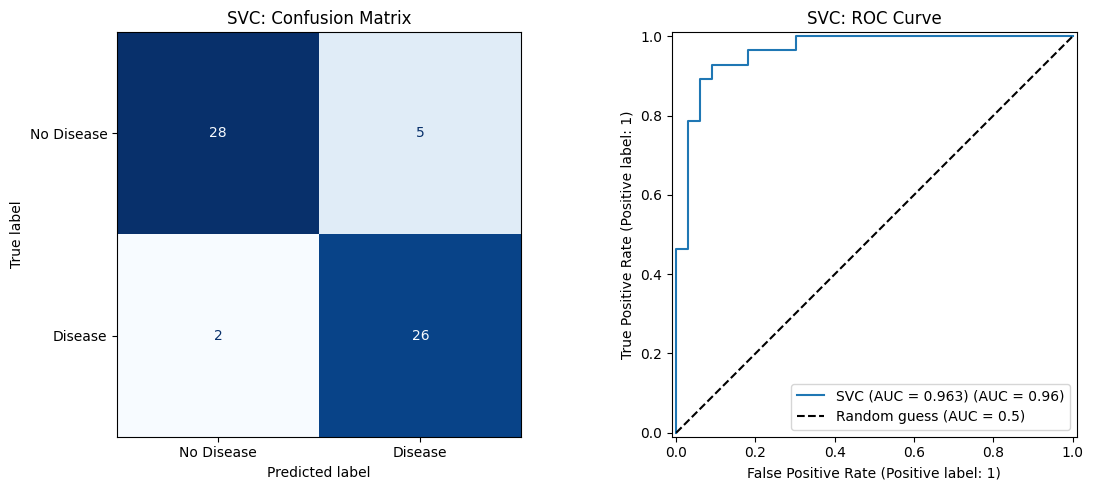

In [5]:
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, RocCurveDisplay, accuracy_score,
                             precision_score, recall_score, f1_score)

class_names = ["No Disease", "Disease"]

svc_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("svc", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
])

svc_pipeline.fit(X_train, y_train)

y_pred_svc = svc_pipeline.predict(X_test)
y_proba_svc = svc_pipeline.predict_proba(X_test)[:, 1]

print("SVC (RBF kernel): Classification Report")
print(classification_report(y_test, y_pred_svc, target_names=class_names, digits=3))
svc_auc = roc_auc_score(y_test, y_proba_svc)
print(f"ROC-AUC: {svc_auc:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_svc),
                       display_labels=class_names).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("SVC: Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, y_proba_svc, name=f"SVC (AUC = {svc_auc:.3f})", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
axes[1].set_title("SVC: ROC Curve")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

results = {"SVC (RBF)": {
    "Accuracy": accuracy_score(y_test, y_pred_svc),
    "Precision": precision_score(y_test, y_pred_svc),
    "Recall": recall_score(y_test, y_pred_svc),
    "F1-score": f1_score(y_test, y_pred_svc),
    "ROC-AUC": svc_auc,
}}

- This piece of code trains an SVC model to predict whether a patient has heart disease. The model uses kernel='rbf' so it can draw a curved line between the groups, and probability=True so it can give a percent chance of heart disease. It then tests the model and shows how well it did with a confusion matrix, a classification report, and a ROC curve.

**Task 6: Instantiate and Train (DTC)**

Decision Tree: Classification Report
              precision    recall  f1-score   support

  No Disease      0.828     0.727     0.774        33
     Disease      0.719     0.821     0.767        28

    accuracy                          0.770        61
   macro avg      0.773     0.774     0.770        61
weighted avg      0.778     0.770     0.771        61

ROC-AUC: 0.873


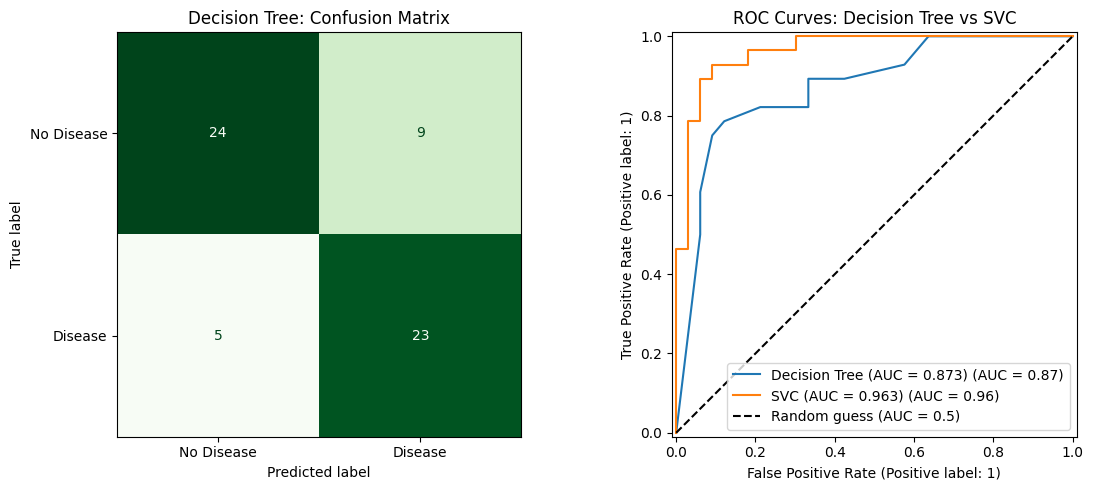

Model comparison on the test set:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
SVC (RBF),0.885,0.839,0.929,0.881,0.963
Decision Tree,0.770,0.719,0.821,0.767,0.873


In [6]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE)),
])

dt_pipeline.fit(X_train, y_train)
y_pred_dt = dt_pipeline.predict(X_test)
y_proba_dt = dt_pipeline.predict_proba(X_test)[:, 1]

print("Decision Tree: Classification Report")
print(classification_report(y_test, y_pred_dt, target_names=class_names, digits=3))
dt_auc = roc_auc_score(y_test, y_proba_dt)
print(f"ROC-AUC: {dt_auc:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_dt),
                       display_labels=class_names).plot(ax=axes[0], cmap="Greens", colorbar=False)
axes[0].set_title("Decision Tree: Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, y_proba_dt, name=f"Decision Tree (AUC = {dt_auc:.3f})", ax=axes[1])
RocCurveDisplay.from_predictions(y_test, y_proba_svc, name=f"SVC (AUC = {svc_auc:.3f})", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
axes[1].set_title("ROC Curves: Decision Tree vs SVC")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

results["Decision Tree"] = {
    "Accuracy": accuracy_score(y_test, y_pred_dt),
    "Precision": precision_score(y_test, y_pred_dt),
    "Recall": recall_score(y_test, y_pred_dt),
    "F1-score": f1_score(y_test, y_pred_dt),
    "ROC-AUC": dt_auc,
}
comparison = pd.DataFrame(results).T.round(3)
print("Model comparison on the test set:")
display(comparison)

- This piece of code trains a Decision Tree model on the same data so it can be compared to the SVC. It's tested the same way as the model above and a table shows the results of both models side by side.

**Task 7: Perform Hyperparameter Tuning**

Best parameters:       {'svc__C': 100, 'svc__gamma': 0.001}
Best CV ROC-AUC:       0.907
Default SVC CV ROC-AUC (C=1, gamma='scale'): 0.883


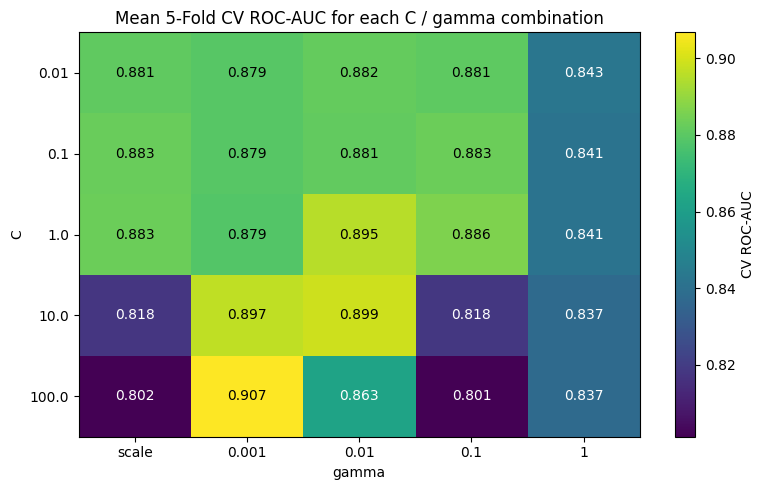

Tuned SVC: Classification Report (test set)
              precision    recall  f1-score   support

  No Disease      0.871     0.818     0.844        33
     Disease      0.800     0.857     0.828        28

    accuracy                          0.836        61
   macro avg      0.835     0.838     0.836        61
weighted avg      0.838     0.836     0.836        61

Updated model comparison on the test set:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
SVC (RBF),0.885,0.839,0.929,0.881,0.963
Decision Tree,0.770,0.719,0.821,0.767,0.873
Tuned SVC (GridSearchCV),0.836,0.800,0.857,0.828,0.947


In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "svc__C": [0.01, 0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.001, 0.01, 0.1, 1],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(estimator=svc_pipeline, param_grid=param_grid,
                           cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True)
grid_search.fit(X_train, y_train)

print(f"Best parameters:       {grid_search.best_params_}")
print(f"Best CV ROC-AUC:       {grid_search.best_score_:.3f}")
baseline_cv = grid_search.cv_results_["mean_test_score"][
    [i for i, p in enumerate(grid_search.cv_results_["params"])
     if p == {"svc__C": 1, "svc__gamma": "scale"}][0]]
print(f"Default SVC CV ROC-AUC (C=1, gamma='scale'): {baseline_cv:.3f}")

cv_results = pd.DataFrame(grid_search.cv_results_)
heatmap = cv_results.pivot_table(index="param_svc__C", columns="param_svc__gamma",
                                 values="mean_test_score")
heatmap = heatmap[["scale", 0.001, 0.01, 0.1, 1]]
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(heatmap.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(heatmap.shape[1]), labels=[str(g) for g in heatmap.columns])
ax.set_yticks(range(heatmap.shape[0]), labels=[str(c) for c in heatmap.index])
for i in range(heatmap.shape[0]):
    for j in range(heatmap.shape[1]):
        ax.text(j, i, f"{heatmap.values[i, j]:.3f}", ha="center", va="center",
                color="white" if heatmap.values[i, j] < heatmap.values.mean() else "black")
ax.set_xlabel("gamma"); ax.set_ylabel("C")
ax.set_title("Mean 5-Fold CV ROC-AUC for each C / gamma combination")
fig.colorbar(im, ax=ax, label="CV ROC-AUC")
plt.tight_layout()
plt.show()

best_svc = grid_search.best_estimator_
y_pred_best = best_svc.predict(X_test)
y_proba_best = best_svc.predict_proba(X_test)[:, 1]
print("Tuned SVC: Classification Report (test set)")
print(classification_report(y_test, y_pred_best, target_names=class_names, digits=3))

results["Tuned SVC (GridSearchCV)"] = {
    "Accuracy": accuracy_score(y_test, y_pred_best),
    "Precision": precision_score(y_test, y_pred_best),
    "Recall": recall_score(y_test, y_pred_best),
    "F1-score": f1_score(y_test, y_pred_best),
    "ROC-AUC": roc_auc_score(y_test, y_proba_best),
}
print("Updated model comparison on the test set:")
display(pd.DataFrame(results).T.round(3))

- This piece of code uses GridSearchCV to try different settings for C and gamma to find the ones that make the SVC work best. It tests every combination with cross-validation and shows the best settings and how the tuned model did.

**Task 8: Generate a Decision Tree Visualization**

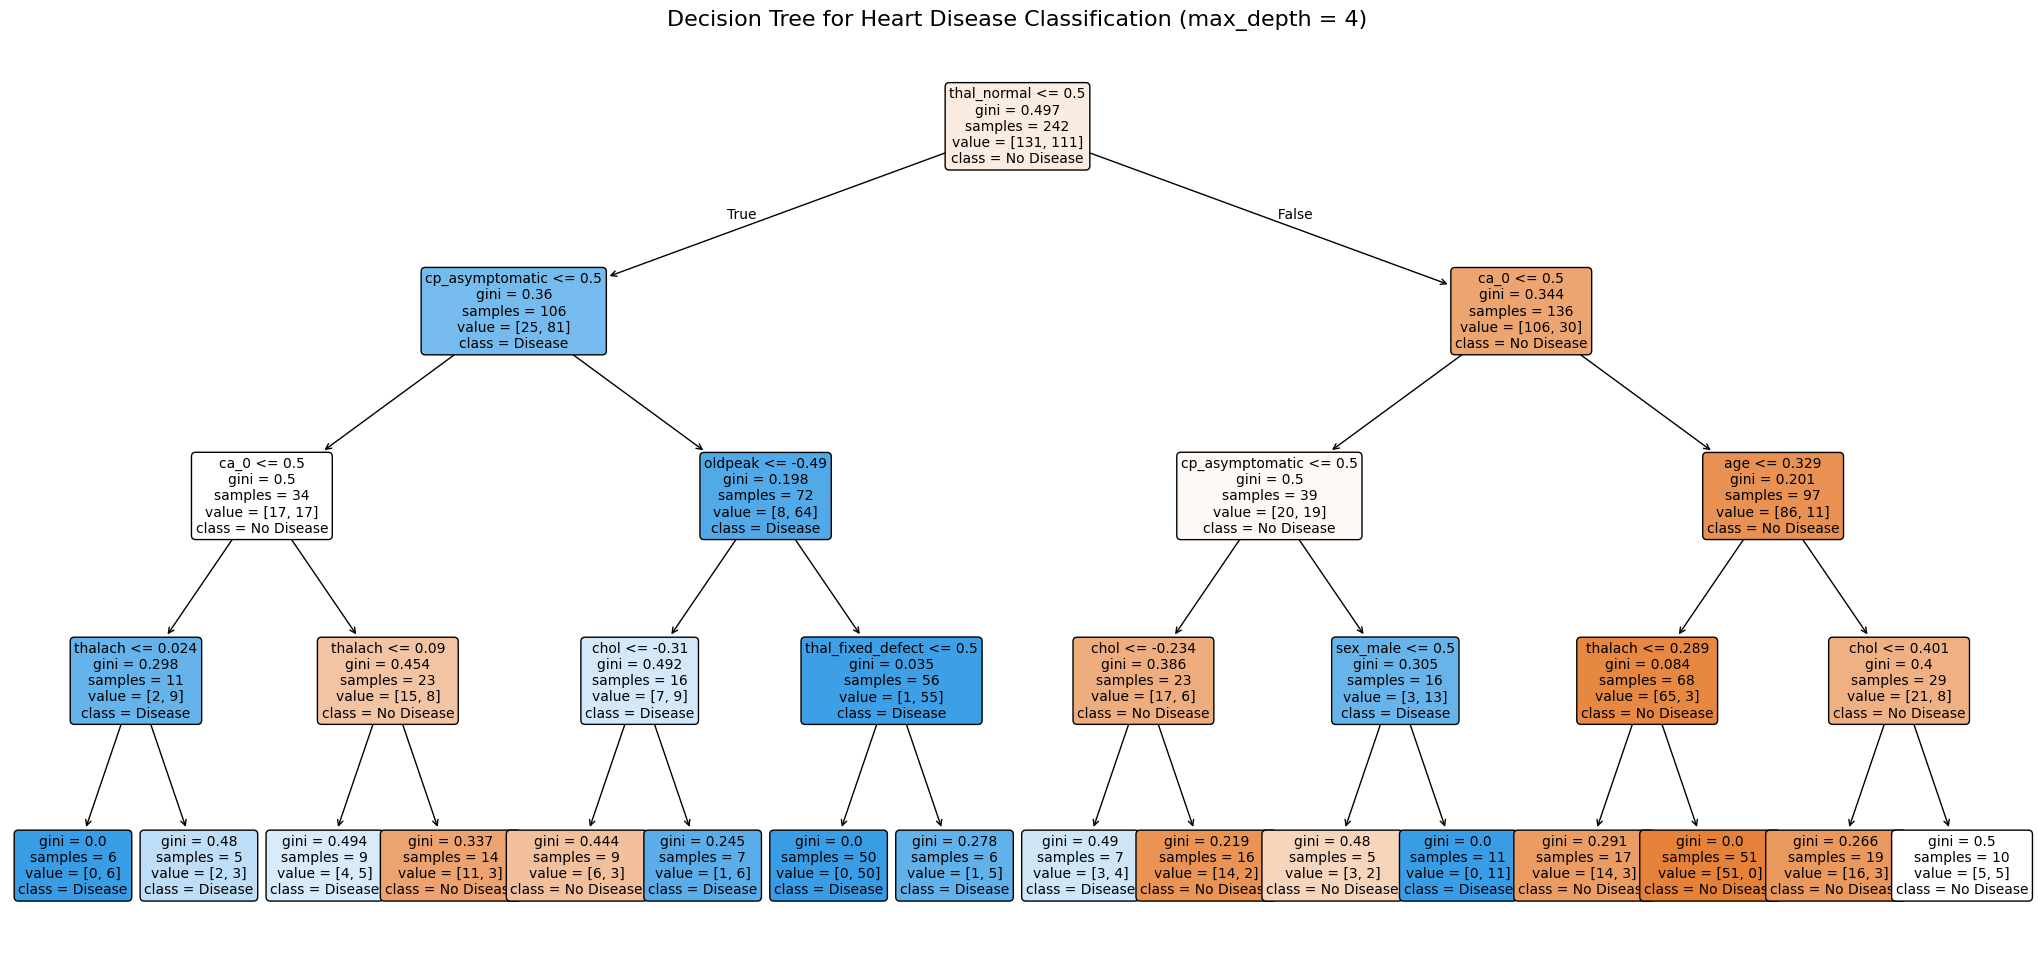

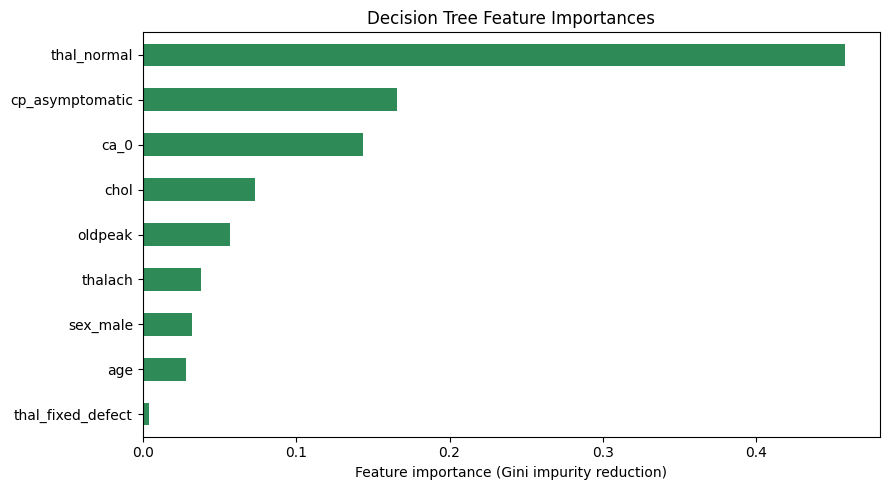

The tree uses 9 of 25 engineered features.
Root split feature: thal_normal


,importance
thal_normal,0.458
cp_asymptomatic,0.165
ca_0,0.144
chol,0.073
oldpeak,0.057
thalach,0.038
sex_male,0.032
age,0.028
thal_fixed_defect,0.004


In [8]:
from sklearn.tree import plot_tree

tree_model = dt_pipeline.named_steps["tree"]
tree_features = [name.split("__", 1)[1]
                 for name in dt_pipeline.named_steps["preprocessor"].get_feature_names_out()]

plt.figure(figsize=(26, 12))
plot_tree(tree_model, feature_names=tree_features, class_names=class_names,
          filled=True, rounded=True, impurity=True, proportion=False, fontsize=10)
plt.title("Decision Tree for Heart Disease Classification (max_depth = 4)", fontsize=16)
plt.show()

importances = (pd.Series(tree_model.feature_importances_, index=tree_features)
                 .sort_values(ascending=False))

used = importances[importances > 0]
fig, ax = plt.subplots(figsize=(9, 5))
used.sort_values().plot(kind="barh", ax=ax, color="seagreen")
ax.set_xlabel("Feature importance (Gini impurity reduction)")
ax.set_title("Decision Tree Feature Importances")
plt.tight_layout()
plt.show()

print(f"The tree uses {len(used)} of {len(importances)} engineered features.")
print(f"Root split feature: {tree_features[tree_model.tree_.feature[0]]}")
display(used.round(3).to_frame("importance"))

- This piece of code draws the decision tree so you can see how it decides if a patient has heart disease. It also shows which features were the most important in making that decision.